# Custom Phase Legends

`binplot`, `ternplot` and the plotting functions of `pycalphad.mapping` color the phases with a *legend generator*: a function that takes the names of the phases on the diagram and returns the legend handles and a dictionary mapping each phase name to its color. The default, `pycalphad.plot.utils.phase_legend`, assigns colors in the (sorted) order of the phases present, and labels them with their database names. So the same phase can get a different color in different diagrams.

Passing your own legend generator gives fixed colors and labels of your choice, the same in every diagram.

In [1]:
from pycalphad import Database, binplot, variables as v
import matplotlib.pyplot as plt

dbf_alzn = Database('../databases/alzn_mey.tdb')
dbf_almg = Database('../databases/Al-Mg_Zhong.tdb')
conds_alzn = {v.N: 1, v.P: 101325, v.T: (300, 1000, 10), v.X('ZN'): (0, 1, 0.02)}
conds_almg = {v.N: 1, v.P: 101325, v.T: (300, 1000, 10), v.X('MG'): (0, 1, 0.02)}

## The default legend

The Al-Zn and Al-Mg diagrams share the fcc, hcp and liquid phases, but with the default legend they get different colors in each diagram:

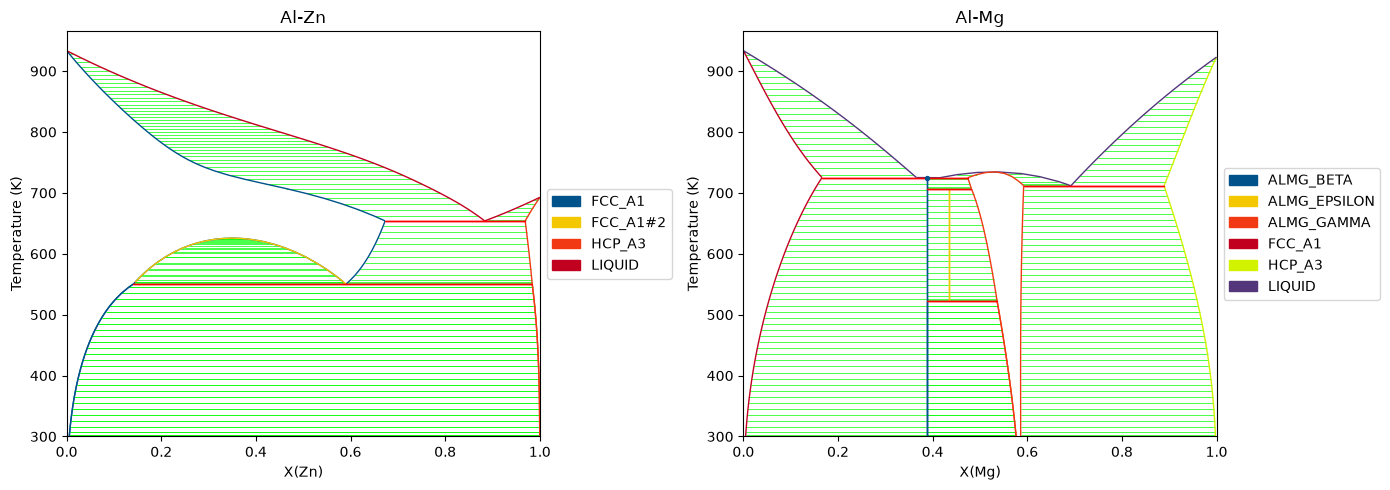

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)
binplot(dbf_alzn, ['AL', 'ZN', 'VA'], list(dbf_alzn.phases), conds_alzn, plot_kwargs={'ax': axes[0]})
binplot(dbf_almg, ['AL', 'MG', 'VA'], list(dbf_almg.phases), conds_almg, plot_kwargs={'ax': axes[1]})
fig.tight_layout()
plt.show()

Al-Zn also shows `FCC_A1#2`: the second composition set of the fcc phase, where the fcc miscibility gap has two fcc phases in equilibrium.

## A legend generator with fixed colors and labels

The legend generator below looks each phase up in a table of labels and colors (phases not in the table keep their database name and are drawn in black). Further composition sets of a phase, such as `FCC_A1#2`, get the color of the phase and no legend entry of their own. Red and green are avoided, because tie triangles and tie lines are drawn in those colors.

In [3]:
import matplotlib.patches as mpatches

PHASE_STYLES = {
    # database name: (legend label, color)
    'LIQUID': ('Liquid', 'tab:blue'),
    'FCC_A1': ('fcc (Al)', 'tab:orange'),
    'HCP_A3': ('hcp (Mg, Zn)', 'tab:purple'),
    'ALMG_BETA': (r'$\beta$ (Al$_3$Mg$_2$)', 'tab:brown'),
    'ALMG_EPSILON': (r'$\varepsilon$ (Al$_{30}$Mg$_{23}$)', 'tab:cyan'),
    'ALMG_GAMMA': (r'$\gamma$ (Al$_{12}$Mg$_{17}$)', 'tab:pink'),
}

def fixed_phase_legend(phases):
    """Legend handles, and a color for each phase name, from PHASE_STYLES."""
    handles, colors, labelled = [], {}, set()
    for phase in phases:
        base = phase.split('#')[0]  # FCC_A1#2 is a further composition set of FCC_A1
        label, color = PHASE_STYLES.get(base, (base, 'black'))
        colors[phase] = color
        if base not in labelled:
            handles.append(mpatches.Patch(color=color, label=label))
            labelled.add(base)
    return handles, colors

Pass it to `binplot` in `plot_kwargs` (or as `legend_generator` to `ternplot` and to the functions in `pycalphad.mapping`, such as `plot_binary`). The shared phases now have the same color and label in both diagrams:

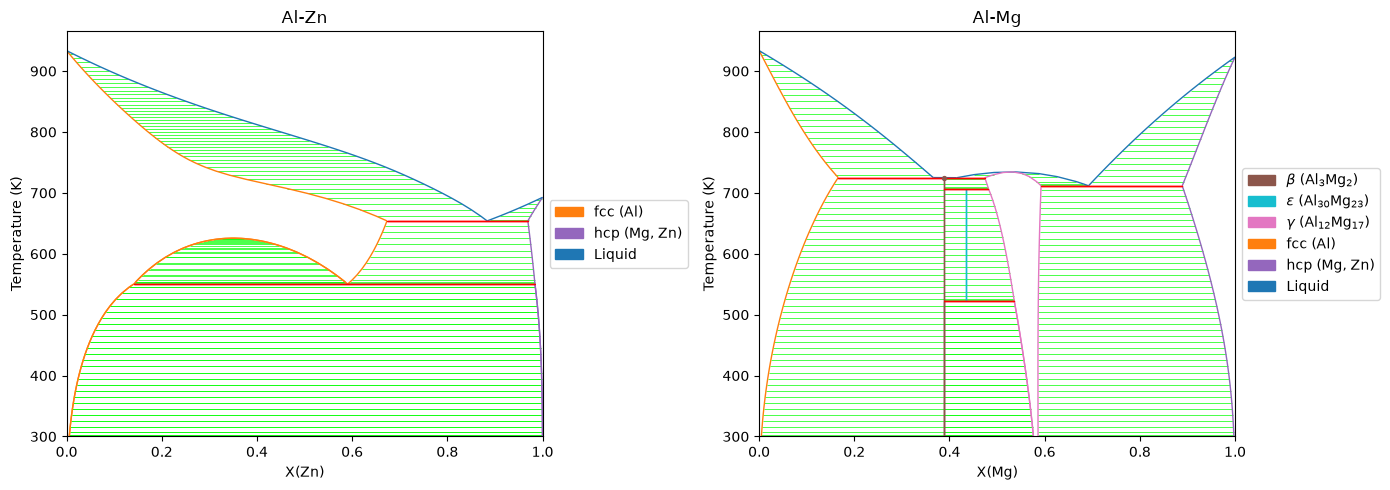

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)
binplot(dbf_alzn, ['AL', 'ZN', 'VA'], list(dbf_alzn.phases), conds_alzn,
        plot_kwargs={'ax': axes[0], 'legend_generator': fixed_phase_legend})
binplot(dbf_almg, ['AL', 'MG', 'VA'], list(dbf_almg.phases), conds_almg,
        plot_kwargs={'ax': axes[1], 'legend_generator': fixed_phase_legend})
fig.tight_layout()
plt.show()